# Density Plot (KDE)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

A smoothed, continuous estimate of a distribution (kernel density estimate). With no bin edges it shows shape clearly, and two or three groups can overlay without the clutter of overlapping bars.

## When to use

- Compare the shapes of two or three distributions on one axis
- Show a smooth shape when the bin choice would distract

## Avoid when

- The sample is small (the smoothing invents shape)
- The data is bounded (e.g. ≥ 0) and the curve would spill past the bound
- The audience is unfamiliar with density (the y-axis is not a count)

## Alternatives

- Histogram
- Ridgeline plot
- Violin plot

## Example

Exam scores of three classes taught with different methods (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })

### Data

In [2]:
rng = np.random.default_rng(14)
df = pd.concat([
    pd.DataFrame({"score": rng.normal(68, 9, 300), "method": "Lecture"}),
    pd.DataFrame({"score": rng.normal(74, 7, 300), "method": "Flipped"}),
    pd.DataFrame({"score": np.r_[rng.normal(60, 6, 150), rng.normal(82, 6, 150)],
                  "method": "Self-paced"}),
], ignore_index=True)
x, hue, order = "score", "method", ["Lecture", "Flipped", "Self-paced"]
labels = dict(x="Exam score", title="Exam score distribution by teaching method")
df.groupby(hue)[x].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
method,,,,,,,,
Flipped,300.0,73.7,6.9,54.0,70.0,73.4,78.0,92.8
Lecture,300.0,68.7,8.7,41.7,63.1,68.7,75.1,92.7
Self-paced,300.0,70.5,12.3,43.6,59.7,70.6,80.8,94.7


### Plot

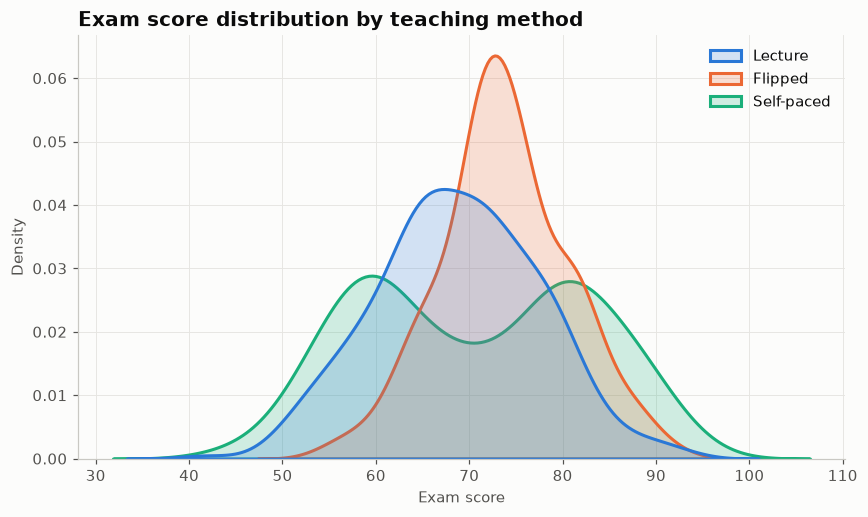

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.kdeplot(data=df, x=x, hue=hue, hue_order=order,
            palette=PALETTE[:len(order)], fill=True, alpha=0.2, linewidth=2, common_norm=False, ax=ax)
ax.set_xlabel(labels["x"])
ax.set_ylabel("Density")
ax.set_title(labels["title"])
ax.get_legend().set_title(None)
fig.tight_layout()
plt.show()

## How to read it

Flipped classes have the highest, tightest peak. Self-paced students split into two groups, one struggling and one excelling, which an average alone would hide.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### altair

In [4]:
import altair as alt
chart = alt.Chart(df).transform_density(
    x, groupby=[hue], as_=[x, "density"], steps=200,
).mark_area(opacity=0.25, line=dict(strokeWidth=2)).encode(
    x=alt.X(f"{x}:Q", title=labels["x"]),
    y=alt.Y("density:Q", title="Density", stack=None),
    color=alt.Color(f"{hue}:N", sort=order, title=None),
).properties(title=labels["title"], width=520, height=300)
chart

alt.Chart(...)

## Try it with real data

**Source:** plotly.express.data.iris() — Fisher's (1936) iris measurements, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
df = px.data.iris()
x, hue, order = "sepal_length", "species", ["setosa", "versicolor", "virginica"]
labels = dict(x="Sepal length (cm)", title="Sepal length by iris species (Fisher, 1936)")
df.groupby(hue)[x].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
setosa,50.0,5.0,0.4,4.3,4.8,5.0,5.2,5.8
versicolor,50.0,5.9,0.5,4.9,5.6,5.9,6.3,7.0
virginica,50.0,6.6,0.6,4.9,6.2,6.5,6.9,7.9


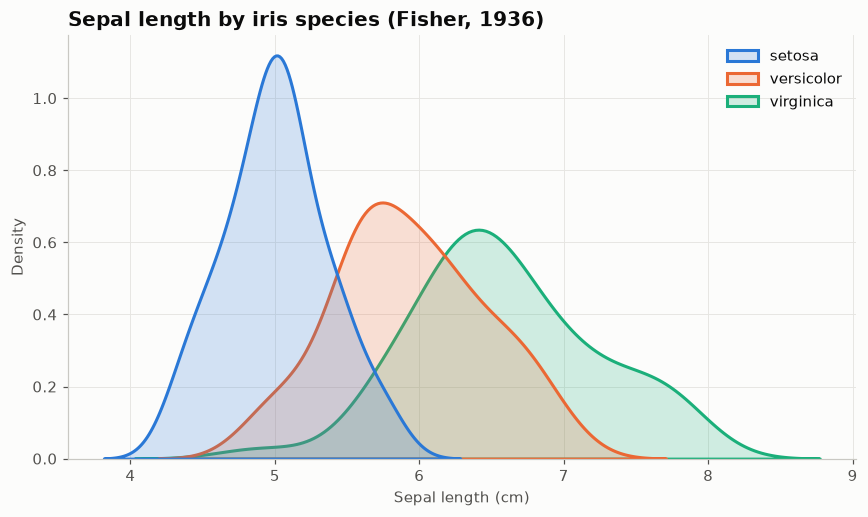

In [6]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.kdeplot(data=df, x=x, hue=hue, hue_order=order,
            palette=PALETTE[:len(order)], fill=True, alpha=0.2, linewidth=2, common_norm=False, ax=ax)
ax.set_xlabel(labels["x"])
ax.set_ylabel("Density")
ax.set_title(labels["title"])
ax.get_legend().set_title(None)
fig.tight_layout()
plt.show()

---
Standalone script: [`kde_density.py`](kde_density.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)